In [1]:
# 1. IMPORTACIÓN DE LIBRERÍAS
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.inspection import permutation_importance

# Configuración de estilo visual para gráficos más profesionales
sns.set_theme(style="whitegrid", palette="muted")

In [2]:
# 2. CARGA Y EXPLORACIÓN DEL CONJUNTO DE DATOS
# Cargar el archivo CSV del dataset de rehabilitación
dfRehab = pd.read_csv('rehabilitation_movement_dataset.csv')

print('Dimensiones del DataFrame:', dfRehab.shape)
print('\nPrimeras filas del dataset:')
display(dfRehab.head(2))

# Verificar información general y tipos de datos
dfRehab.info()

# Verificar si existen valores nulos por columna
print('\nValores nulos por columna:')
print(dfRehab.isnull().sum())

# Estadísticas descriptivas de las variables numéricas
print('\nResumen estadístico:')
display(dfRehab.describe())

Dimensiones del DataFrame: (3000, 33)

Primeras filas del dataset:


,Timestamp (s),Participant_ID,Age (yrs),Gender,Height (cm),Weight (kg),BMI (kg/m²),Obesity_Class,Body_Fat_%,Waist_Circumference (cm),...,Joint_Angle (°),Angular_Velocity (°/s),Stride_Time (s),Step_Length (cm),"Motion_Smoothness (Jerk, m/s³)",Energy_Expenditure (kJ),Feedback_Error (%),Deviation_Level,Performance_Label,Feedback_Action
0,275.549335,P24,58,Male,163.6,76.2,28.47,Overweight,18.349936,108.796394,...,42.249519,59.379264,1.095109,67.844411,3.236930,9.019583,3.36845,Low,Optimal,Maintain
1,297.106146,P47,26,Male,163.2,81.4,30.55,Obese,33.458447,80.351199,...,41.935343,59.191223,0.830664,57.955270,3.145517,6.798873,1.36444,Low,Optimal,Maintain


<class 'pandas.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 33 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Timestamp (s)                   3000 non-null   float64
 1   Participant_ID                  3000 non-null   str    
 2   Age (yrs)                       3000 non-null   int64  
 3   Gender                          3000 non-null   str    
 4   Height (cm)                     3000 non-null   float64
 5   Weight (kg)                     3000 non-null   float64
 6   BMI (kg/m²)                     3000 non-null   float64
 7   Obesity_Class                   3000 non-null   str    
 8   Body_Fat_%                      3000 non-null   float64
 9   Waist_Circumference (cm)        3000 non-null   float64
 10  Rehab_Week                      3000 non-null   int64  
 11  Sensor_ID                       3000 non-null   str    
 12  Body_Segment                    3000 non-null

,Timestamp (s),Age (yrs),Height (cm),Weight (kg),BMI (kg/m²),Body_Fat_%,Waist_Circumference (cm),Rehab_Week,Quaternion_w,Quaternion_x,...,Accel_X (m/s²),Accel_Y (m/s²),Accel_Z (m/s²),Joint_Angle (°),Angular_Velocity (°/s),Stride_Time (s),Step_Length (cm),"Motion_Smoothness (Jerk, m/s³)",Energy_Expenditure (kJ),Feedback_Error (%)
count,3000.000000,3000.000000,3000.000000,3000.000000,3000.00000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,...,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000
mean,298.249622,41.892333,168.219133,69.552167,24.74897,26.626522,90.368275,6.012333,0.850563,-0.000739,...,0.005170,-0.001855,9.824849,51.790064,76.865343,1.097319,65.165404,6.312042,6.477284,8.001715
std,172.212054,13.090016,7.927149,11.970581,4.90379,4.804955,11.402729,3.204518,0.087235,0.172889,...,1.009336,0.989673,1.011661,9.470521,18.045607,0.201091,8.035620,3.169142,2.006903,5.872452
min,0.335456,20.000000,140.600000,24.900000,8.10000,18.008985,70.004646,1.000000,0.700072,-0.299939,...,-3.944594,-3.836656,6.523216,30.454117,43.282751,0.365079,38.187116,1.549238,3.009475,0.005612
25%,154.760451,31.000000,162.900000,61.275000,21.31000,22.584678,80.637133,3.000000,0.774448,-0.147388,...,-0.670008,-0.667931,9.173286,44.913050,62.095133,0.959980,59.781939,3.321984,4.767703,2.679320
50%,293.617011,42.000000,168.100000,69.450000,24.54500,26.488799,90.619507,6.000000,0.849495,0.001174,...,-0.004101,-0.012848,9.803589,49.440710,73.288331,1.099856,65.287490,5.912159,6.513428,7.003183
75%,450.954411,53.000000,173.600000,77.800000,27.99000,30.711746,100.173807,9.000000,0.927860,0.145849,...,0.659554,0.677108,10.505983,57.045314,89.184125,1.230455,70.365185,8.587928,8.212395,12.059029
max,599.611758,64.000000,197.400000,108.300000,44.00000,34.995906,109.992206,11.000000,0.999945,0.299935,...,3.505871,3.470638,13.336048,94.462127,146.078080,1.748619,96.508024,16.366868,9.997599,27.754715



Distribución de clases en Performance_Label:
Performance_Label
Optimal             1000
Slight Deviation    1000
Deviation           1000
Name: count, dtype: int64


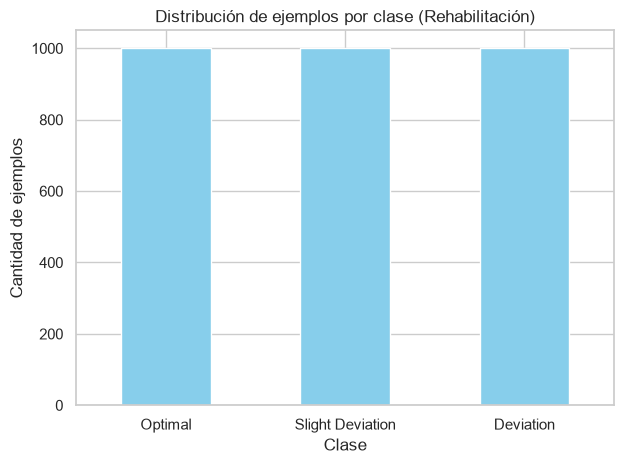

In [3]:
# 3. ANÁLISIS DE LA VARIABLE OBJETIVO (TARGET)
# Definimos la variable objetivo (ej. 'Performance_Label' o 'Deviation_Level')
variable_objetivo = 'Performance_Label'

print(f'\nDistribución de clases en {variable_objetivo}:')
print(dfRehab[variable_objetivo].value_counts())

# Visualizar la distribución de clases
dfRehab[variable_objetivo].value_counts().plot(kind='bar', color='skyblue')
plt.title('Distribución de ejemplos por clase (Rehabilitación)')
plt.xlabel('Clase')
plt.ylabel('Cantidad de ejemplos')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [4]:
# 4. SELECCIÓN DE CARACTERÍSTICAS Y ETIQUETAS
# Seleccionamos únicamente las variables numéricas continuas/discretas como predictoras (X)
# Excluimos IDs, timestamps o etiquetas de texto no procesadas directamente
columnas_excluidas = [
    'Timestamp (s)',
    'Participant_ID',
    'Gender',
    'Sensor_ID',
    'Body_Segment',
    'Obesity_Class',
    'Deviation_Level',
    'Performance_Label',
    'Feedback_Action',
]

X = dfRehab.drop(
    columns=[col for col in columnas_excluidas if col in dfRehab.columns]
)
y = dfRehab[variable_objetivo]

print('\nDimensiones de X (Predictoras):', X.shape)
print('Dimensiones de y (Objetivo):', y.shape)


Dimensiones de X (Predictoras): (3000, 24)
Dimensiones de y (Objetivo): (3000,)


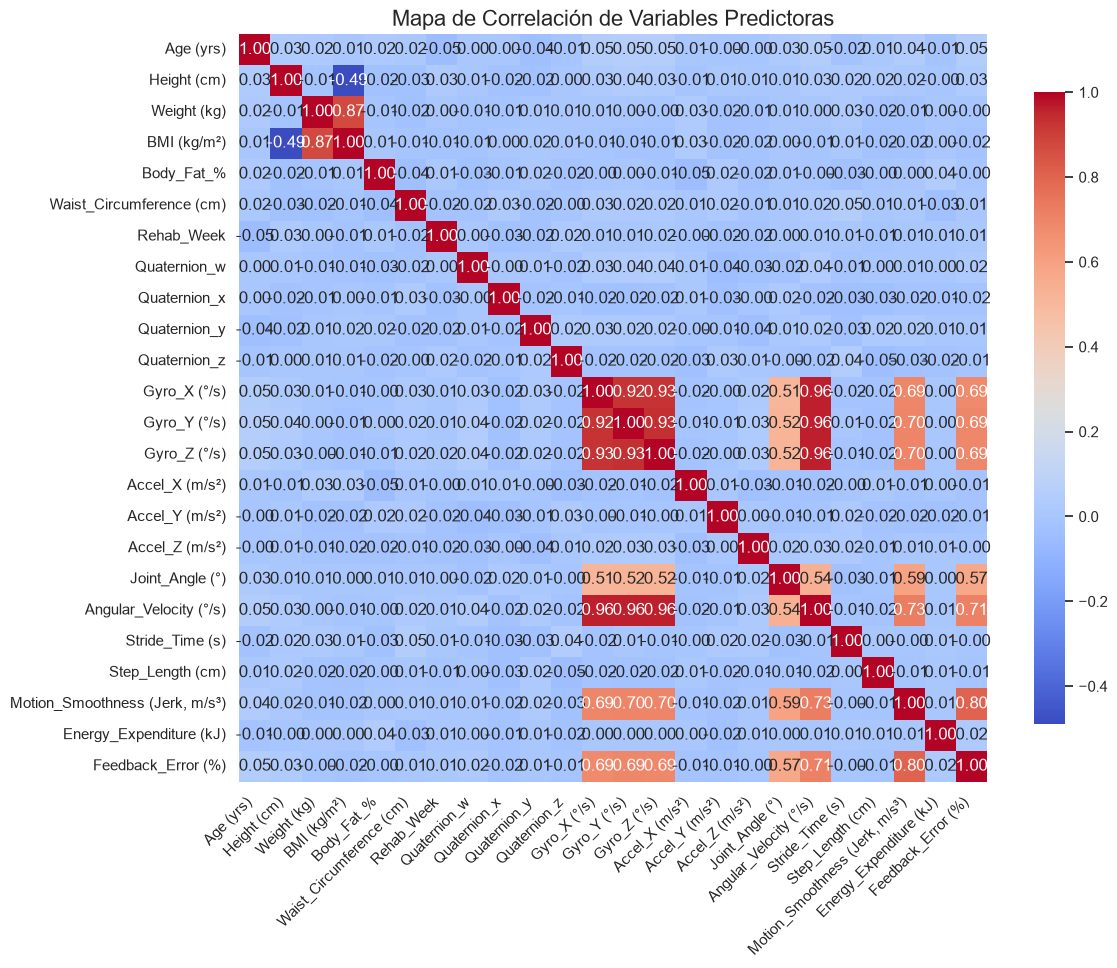

In [5]:
# 4.1 ANÁLISIS DE CORRELACIÓN PARA DESCARTAR VARIABLES
plt.figure(figsize=(12, 10))
matriz_correlacion = X.corr()

# Generar un mapa de calor (heatmap)
sns.heatmap(
    matriz_correlacion, 
    annot=True,          # Muestra los valores
    fmt=".2f",           # 2 decimales
    cmap="coolwarm",     # Escala de colores intuitiva (rojo/azul)
    square=True, 
    cbar_kws={"shrink": .8}
)
plt.title('Mapa de Correlación de Variables Predictoras', fontsize=16)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [6]:
# 5. DIVISIÓN DE DATOS (ENTRENAMIENTO Y PRUEBA)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print('\nConjunto de entrenamiento (X_train):', X_train.shape)
print('Conjunto de prueba (X_test):', X_test.shape)


Conjunto de entrenamiento (X_train): (2400, 24)
Conjunto de prueba (X_test): (600, 24)


In [7]:
# 6. ESCALAMIENTO DE CARACTERÍSTICAS (OBLIGATORIO PARA SVC)
# SVC requiere que todas las características estén en la misma escala (media 0, varianza 1)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [8]:
# 7. ENTRENAMIENTO DEL MODELO SVC
# Usaremos un kernel de tipo RBF (Radial Basis Function), muy robusto para datos no lineales
modelo_svc = SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42)

modelo_svc.fit(X_train_scaled, y_train)
print('\n¡El modelo SVC se entrenó correctamente!')


¡El modelo SVC se entrenó correctamente!


Exactitud (Accuracy): 0.9900

Reporte de Clasificación:
                  precision    recall  f1-score   support

       Deviation       0.99      0.99      0.99       200
         Optimal       0.99      1.00      0.99       200
Slight Deviation       0.99      0.98      0.98       200

        accuracy                           0.99       600
       macro avg       0.99      0.99      0.99       600
    weighted avg       0.99      0.99      0.99       600



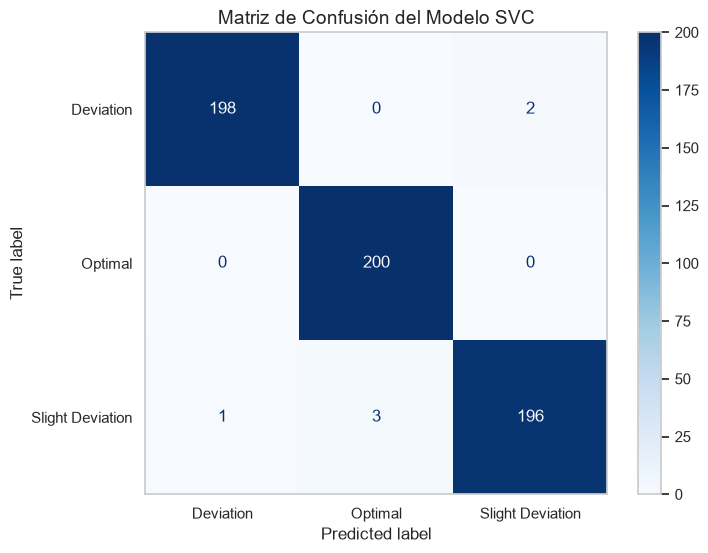

In [9]:
# 8. EVALUACIÓN Y MATRIZ DE CONFUSIÓN VISUAL
y_pred = modelo_svc.predict(X_test_scaled)

print(f"Exactitud (Accuracy): {accuracy_score(y_test, y_pred):.4f}\n")
print('Reporte de Clasificación:')
print(classification_report(y_test, y_pred, target_names=modelo_svc.classes_.astype(str)))

# Crear la matriz de confusión visual
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=modelo_svc.classes_)

fig, ax = plt.subplots(figsize=(8, 6))
disp.plot(cmap='Blues', ax=ax, values_format='d')
plt.title('Matriz de Confusión del Modelo SVC', fontsize=14)
plt.grid(False) # Quitar cuadrícula de fondo para que se vea limpia
plt.show()

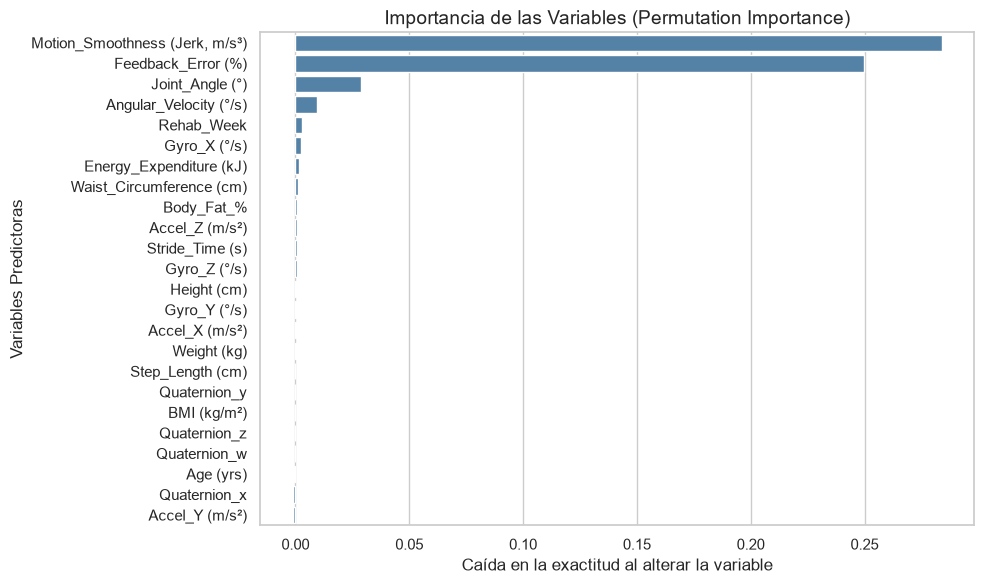


Variables con menor importancia (candidatas a descartar):


,Variable,Importancia_Media,Desviacion
10,Quaternion_z,-0.000167,0.001384
7,Quaternion_w,-0.000333,0.000667
0,Age (yrs),-0.000500,0.001302
8,Quaternion_x,-0.001000,0.001106
15,Accel_Y (m/s²),-0.001167,0.000764


In [10]:
# 9. IMPORTANCIA DE VARIABLES (PARA DESCARTAR CARACTERÍSTICAS)
# Calculamos qué tanto afecta al modelo mezclar los datos de cada variable
resultado_importancia = permutation_importance(
    modelo_svc, X_test_scaled, y_test, n_repeats=10, random_state=42, n_jobs=-1
)

# Organizar los resultados en un DataFrame
df_importancia = pd.DataFrame({
    'Variable': X.columns,
    'Importancia_Media': resultado_importancia.importances_mean,
    'Desviacion': resultado_importancia.importances_std
}).sort_values(by='Importancia_Media', ascending=False)

# Graficar
plt.figure(figsize=(10, 6))
sns.barplot(
    data=df_importancia, 
    x='Importancia_Media', 
    y='Variable', 
    color='steelblue'
)
plt.title('Importancia de las Variables (Permutation Importance)', fontsize=14)
plt.xlabel('Caída en la exactitud al alterar la variable')
plt.ylabel('Variables Predictoras')
plt.tight_layout()
plt.show()

print("\nVariables con menor importancia (candidatas a descartar):")
display(df_importancia.tail(5))